# Anime Recommender

User-based collaborative filtering, content-based filtering, a weighted hybrid and Surprise SVD, built on MyAnimeList user ratings and evaluated against simple baselines on a shared held-out test set.

Run from the `content_recommender/` folder with the `anime-recommender` environment (see `README.md`).

In [1]:
import subprocess
import sys
from math import sqrt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import iqr, skew, kurtosis

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer

from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import GridSearchCV

import warnings
warnings.filterwarnings('ignore')

In [2]:
DATA_RAW = Path("data/raw")
DATA_EXTERNAL = Path("data/external")
DATA_PROCESSED = Path("data/processed")
ARTIFACTS = Path("artifacts")
FIGURES = Path("figures")

for folder in (DATA_PROCESSED, ARTIFACTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EXAMPLE_USER = "u1852"

## Read in data and remove duplicates based on user

In [3]:
ratings_df = pd.read_csv(DATA_RAW / "user_anime_ratings_wide.csv.gz")
ratings_df.head()

,user,Sword Art Online Movie: Ordinal Scale,Death Note,Golden Time,Shingeki no Kyojin: The Final Season Part 2,Fullmetal Alchemist: Brotherhood,Mushoku Tensei: Isekai Ittara Honki Dasu,Ore dake Level Up na Ken,Date A Live III,Dragon Ball Super: Broly,Fate/stay night: Unlimited Blade Works,Hametsu no Oukoku,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka II,Kuzu no Honkai,Enen no Shouboutai: Ni no Shou,Shingeki no Kyojin Season 3,Witch Craft Works,No Game No Life,Baki: Dai Raitaisai-hen,Tate no Yuusha no Nariagari Season 2,Vinland Saga,"Keikenzumi na Kimi to, Keiken Zero na Ore ga, Otsukiai suru Hanashi.",Boku no Kokoro no Yabai Yatsu,Naruto: Shippuuden,Shokugeki no Souma: Ni no Sara,Vivy: Fluorite Eye's Song,Tomodachi Game,Hataage! Kemono Michi,Gokushufudou,Ano Hi Mita Hana no Namae wo Bokutachi wa Mada Shiranai.,High School DxD BorN,Sousou no Frieren,One Punch Man 2nd Season,Death Parade,Youjo Senki,86 Part 2,Paripi Koumei,Black Clover: Mahou Tei no Ken,Code Geass: Fukkatsu no Lelouch,High School DxD,Koi wa Ameagari no You ni,Kaguya-sama wa Kokurasetai? Tensai-tachi no Renai Zunousen,High School DxD New,Tsugumomo,Saijaku Muhai no Bahamut,Boku no Hero Academia 6th Season,Kono Subarashii Sekai ni Shukufuku wo!,Mushoku Tensei: Isekai Ittara Honki Dasu Part 2,Overlord III,Shigatsu wa Kimi no Uso,Dragon Ball Z,Shuumatsu no Walküre II,Bocchi the Rock!,Enen no Shouboutai,Re:Zero kara Hajimeru Isekai Seikatsu 2nd Season Part 2,Sword Art Online: Alicization - War of Underworld 2nd Season,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri Part 2",Seishun Buta Yarou wa Bunny Girl Senpai no Yume wo Minai,Nanatsu no Taizai: Imashime no Fukkatsu,Mairimashita! Iruma-kun,Tensei shitara Slime Datta Ken 3rd Season,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri",Mashle,Akame ga Kill!,Bleach: Sennen Kessen-hen,Grand Blue,Yakusoku no Neverland,"Ijiranaide, Nagatoro-san","Kanojo, Okarishimasu",Tensei shitara Slime Datta Ken 2nd Season Part 2,Kanojo mo Kanojo,Shingeki no Kyojin Season 3 Part 2,Kimi no Suizou wo Tabetai,Horimiya: Piece,Kimetsu no Yaiba: Yuukaku-hen,Net-juu no Susume,Shingeki no Kyojin: The Final Season,Steins;Gate 0,Kage no Jitsuryokusha ni Naritakute! 2nd Season,Nazo no Kanojo X,Dr. Stone,86,Nekopara,Hataraku Maou-sama!,Jujutsu Kaisen 2nd Season,Gamers!,Shokugeki no Souma: San no Sara,Sword Art Online II,Nanatsu no Taizai: Kamigami no Gekirin,5-toubun no Hanayome ∬,Log Horizon,Bakemonogatari,Shokugeki no Souma: San no Sara - Tootsuki Ressha-hen,Blood-C,3D Kanojo: Real Girl,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka IV: Shin Shou - Yakusai-hen,Re:Zero kara Hajimeru Isekai Seikatsu,Arifureta Shokugyou de Sekai Saikyou,Bleach,Nijiiro Days,Boku no Hero Academia 4th Season,"Kanojo, Okarishimasu Petit 2nd Season",Boku no Hero Academia 2nd Season,Fate/Zero 2nd Season,Chobits,Yahari Ore no Seishun Love Comedy wa Machigatteiru. Zoku,Shimoneta to Iu Gainen ga Sonzai Shinai Taikutsu na Sekai,"Ore ga Ojousama Gakkou ni ""Shomin Sample"" Toshite Gets♥Sareta Ken",Tokyo Revengers,Kishuku Gakkou no Juliet,Ragna Crimson,Kimetsu no Yaiba: Katanakaji no Sato-hen,Overlord,Tensai Ouji no Akaji Kokka Saisei Jutsu,Nisekoi:,Plastic Memories,Nisekoi,Genjitsu Shugi Yuusha no Oukoku Saikenki,"Sentouin, Hakenshimasu!",Toradora!,Lovely★Complex,Shingeki no Kyojin: The Final Season - Kanketsu-hen,Boku no Hero Academia 7th Season,Megami no Café Terrace,Gokushufudou Season 2,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka IV: Shin Shou - Meikyuu-hen,Dragon Ball Super,Bokutachi wa Benkyou ga Dekinai,Tensei shitara Slime Datta Ken Movie: Guren no Kizuna-hen,Mirai Nikki (TV),Gabriel DropOut,Ore Monogatari!!,Overlord IV,Rosario to Vampire,5-toubun no Hanayome,One Piece Film: Red,Mashle: Shinkakusha Kouho Senbatsu Shiken-hen,Boku no Hero Academia,Fate/stay night Movie: Heaven's Feel - III. Spring Song,Fairy Tail,Elfen Lied,Overlord II,Saenai Heroine no Sodatekata ♭,Amagi Brilliant Park,Chain

In [4]:
print(ratings_df["user"].nunique())
print(ratings_df.shape[0])

5034
5610


In [5]:
ratings_df.drop_duplicates(subset=["user"], inplace=True)
print(ratings_df["user"].nunique())
print(ratings_df.shape[0])

5034
5034


# EDA

## Matrix Sparsity

In [6]:
# Rating cells only (the user column is not part of the matrix)
rating_cells = ratings_df.drop(columns="user")

# Total number of entries in the matrix
total_entries = rating_cells.shape[0] * rating_cells.shape[1]

# Count the number of non-missing entries
non_missing_entries = rating_cells.count().sum()

# Calculate sparsity
sparsity = 1 - (non_missing_entries / total_entries)

print(f"Sparsity of the matrix: {sparsity:.2%}")

Sparsity of the matrix: 98.68%


## Anonymise users

In [7]:
# Usernames were already replaced with random IDs by scripts/anonymise_users.py
ratings_anon_df = ratings_df.rename(columns={"user": "user_id"})

ratings_anon_df.head(10)

,user_id,Sword Art Online Movie: Ordinal Scale,Death Note,Golden Time,Shingeki no Kyojin: The Final Season Part 2,Fullmetal Alchemist: Brotherhood,Mushoku Tensei: Isekai Ittara Honki Dasu,Ore dake Level Up na Ken,Date A Live III,Dragon Ball Super: Broly,Fate/stay night: Unlimited Blade Works,Hametsu no Oukoku,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka II,Kuzu no Honkai,Enen no Shouboutai: Ni no Shou,Shingeki no Kyojin Season 3,Witch Craft Works,No Game No Life,Baki: Dai Raitaisai-hen,Tate no Yuusha no Nariagari Season 2,Vinland Saga,"Keikenzumi na Kimi to, Keiken Zero na Ore ga, Otsukiai suru Hanashi.",Boku no Kokoro no Yabai Yatsu,Naruto: Shippuuden,Shokugeki no Souma: Ni no Sara,Vivy: Fluorite Eye's Song,Tomodachi Game,Hataage! Kemono Michi,Gokushufudou,Ano Hi Mita Hana no Namae wo Bokutachi wa Mada Shiranai.,High School DxD BorN,Sousou no Frieren,One Punch Man 2nd Season,Death Parade,Youjo Senki,86 Part 2,Paripi Koumei,Black Clover: Mahou Tei no Ken,Code Geass: Fukkatsu no Lelouch,High School DxD,Koi wa Ameagari no You ni,Kaguya-sama wa Kokurasetai? Tensai-tachi no Renai Zunousen,High School DxD New,Tsugumomo,Saijaku Muhai no Bahamut,Boku no Hero Academia 6th Season,Kono Subarashii Sekai ni Shukufuku wo!,Mushoku Tensei: Isekai Ittara Honki Dasu Part 2,Overlord III,Shigatsu wa Kimi no Uso,Dragon Ball Z,Shuumatsu no Walküre II,Bocchi the Rock!,Enen no Shouboutai,Re:Zero kara Hajimeru Isekai Seikatsu 2nd Season Part 2,Sword Art Online: Alicization - War of Underworld 2nd Season,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri Part 2",Seishun Buta Yarou wa Bunny Girl Senpai no Yume wo Minai,Nanatsu no Taizai: Imashime no Fukkatsu,Mairimashita! Iruma-kun,Tensei shitara Slime Datta Ken 3rd Season,"Gate: Jieitai Kanochi nite, Kaku Tatakaeri",Mashle,Akame ga Kill!,Bleach: Sennen Kessen-hen,Grand Blue,Yakusoku no Neverland,"Ijiranaide, Nagatoro-san","Kanojo, Okarishimasu",Tensei shitara Slime Datta Ken 2nd Season Part 2,Kanojo mo Kanojo,Shingeki no Kyojin Season 3 Part 2,Kimi no Suizou wo Tabetai,Horimiya: Piece,Kimetsu no Yaiba: Yuukaku-hen,Net-juu no Susume,Shingeki no Kyojin: The Final Season,Steins;Gate 0,Kage no Jitsuryokusha ni Naritakute! 2nd Season,Nazo no Kanojo X,Dr. Stone,86,Nekopara,Hataraku Maou-sama!,Jujutsu Kaisen 2nd Season,Gamers!,Shokugeki no Souma: San no Sara,Sword Art Online II,Nanatsu no Taizai: Kamigami no Gekirin,5-toubun no Hanayome ∬,Log Horizon,Bakemonogatari,Shokugeki no Souma: San no Sara - Tootsuki Ressha-hen,Blood-C,3D Kanojo: Real Girl,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka IV: Shin Shou - Yakusai-hen,Re:Zero kara Hajimeru Isekai Seikatsu,Arifureta Shokugyou de Sekai Saikyou,Bleach,Nijiiro Days,Boku no Hero Academia 4th Season,"Kanojo, Okarishimasu Petit 2nd Season",Boku no Hero Academia 2nd Season,Fate/Zero 2nd Season,Chobits,Yahari Ore no Seishun Love Comedy wa Machigatteiru. Zoku,Shimoneta to Iu Gainen ga Sonzai Shinai Taikutsu na Sekai,"Ore ga Ojousama Gakkou ni ""Shomin Sample"" Toshite Gets♥Sareta Ken",Tokyo Revengers,Kishuku Gakkou no Juliet,Ragna Crimson,Kimetsu no Yaiba: Katanakaji no Sato-hen,Overlord,Tensai Ouji no Akaji Kokka Saisei Jutsu,Nisekoi:,Plastic Memories,Nisekoi,Genjitsu Shugi Yuusha no Oukoku Saikenki,"Sentouin, Hakenshimasu!",Toradora!,Lovely★Complex,Shingeki no Kyojin: The Final Season - Kanketsu-hen,Boku no Hero Academia 7th Season,Megami no Café Terrace,Gokushufudou Season 2,Dungeon ni Deai wo Motomeru no wa Machigatteiru Darou ka IV: Shin Shou - Meikyuu-hen,Dragon Ball Super,Bokutachi wa Benkyou ga Dekinai,Tensei shitara Slime Datta Ken Movie: Guren no Kizuna-hen,Mirai Nikki (TV),Gabriel DropOut,Ore Monogatari!!,Overlord IV,Rosario to Vampire,5-toubun no Hanayome,One Piece Film: Red,Mashle: Shinkakusha Kouho Senbatsu Shiken-hen,Boku no Hero Academia,Fate/stay night Movie: Heaven's Feel - III. Spring Song,Fairy Tail,Elfen Lied,Overlord II,Saenai Heroine no Sodatekata ♭,Amagi Brilliant Park,Ch

## Change to melted format

In [8]:
# Melt to user-item-rating triplets, keeping only the rated cells
# (melting the full ~105M-cell grid before dropping NaNs needs several GB of memory)
values = ratings_anon_df.drop(columns="user_id").to_numpy(dtype=np.float32)
user_pos, anime_pos = np.nonzero(~np.isnan(values))

ratings_melted = pd.DataFrame({
    "user_id": ratings_anon_df["user_id"].to_numpy()[user_pos],
    "anime_title": ratings_anon_df.columns[1:].to_numpy()[anime_pos],
    "rating": values[user_pos, anime_pos],
})
ratings_melted = ratings_melted.sort_values(by=["user_id", "anime_title"]).reset_index(drop=True)
print(f"{ratings_melted.shape[0]} rows after melting df")

# The wide frames are no longer needed
del ratings_df, ratings_anon_df, rating_cells, values

1387414 rows after melting df


In [9]:
ratings_melted.head()

,user_id,anime_title,rating
0,u0003,"""Bungaku Shoujo"" Memoire",8.0
1,u0003,"""Oshi no Ko""",9.0
2,u0003,"""Oshi no Ko"" 2nd Season",9.0
3,u0003,.hack//Sign,7.0
4,u0003,100-man no Inochi no Ue ni Ore wa Tatteiru,9.0


## Filtering based on stats (mean and median)

|           |           | **Raw** | **Filtered** |
|-----------|-----------|---------|-------------|
| **Users** | Mean      | 282     | 360         |
|           | Median    | 170     | 252         |
|           | Total     | 16266   | 3506        |
| **Anime** | Mean      | 85      | 228         |
|           | Median    | 9       | 99          |
|           | Total     | 4915    | 5535        |

In [10]:
# Count the occurrences of each value
user_value_counts = ratings_melted['user_id'].value_counts()
anime_value_counts = ratings_melted['anime_title'].value_counts()

print(f"Median user count: {np.median(user_value_counts)}")
print(f"Mean user count: {np.mean(user_value_counts)}")

print(f"Median anime count: {np.median(anime_value_counts):.0f}")
print(f"Mean anime count: {np.mean(anime_value_counts):.0f}")

Median user count: 170.0
Mean user count: 282.2815869786368
Median anime count: 9
Mean anime count: 85


#### Filtering data under threshold based on appearance count

In [11]:
# Filter the DataFrame based on how many times a user has rated something and for anime that appear more than n number of times
min_user_appearances = 85
min_anime_appearances = 25

filtered_data_user = ratings_melted[ratings_melted['user_id'].isin(user_value_counts[user_value_counts >= min_user_appearances].index)]
filtered_data = filtered_data_user[filtered_data_user['anime_title'].isin(anime_value_counts[anime_value_counts >= min_anime_appearances].index)]

print(f"Users before filtering: {ratings_melted['user_id'].nunique()}")
print(f"Users after filtering: {filtered_data['user_id'].nunique()}")
print("\n")
print(f"Anime before filtering: {ratings_melted['anime_title'].nunique()}")
print(f"Anime after filtering: {filtered_data['anime_title'].nunique()}")
print("\n")

filtered_user_value_counts = filtered_data['user_id'].value_counts()
filtered_anime_value_counts = filtered_data['anime_title'].value_counts()

print(f"Median user count: {np.median(filtered_user_value_counts)}")
print(f"Mean user count: {np.mean(filtered_user_value_counts)}")

print(f"Median anime count: {np.median(filtered_anime_value_counts):.0f}")
print(f"Mean anime count: {np.mean(filtered_anime_value_counts):.0f}")
print("\n")
print(f"{ratings_melted.shape[0] - filtered_data.shape[0]} Rows removed")

print(f"Filtered df has {filtered_data.shape[0]} rows")

Users before filtering: 4915
Users after filtering: 3506


Anime before filtering: 16266


Anime after filtering: 5535




Median user count: 252.0
Mean user count: 360.16742726754137
Median anime count: 99
Mean anime count: 228


124667 Rows removed
Filtered df has 1262747 rows


#### Compute mean / median stats for comparison

In [12]:
# Compute raw statistics
user_mean = np.mean(user_value_counts)
user_median = np.median(user_value_counts)

anime_mean = np.mean(anime_value_counts)
anime_median = np.median(anime_value_counts)

user_iqr = iqr(user_value_counts)
q3_user = np.percentile(user_value_counts, 75)
user_outlier_threshold = q3_user + 1.5 * user_iqr

anime_iqr = iqr(anime_value_counts)
q3_anime = np.percentile(anime_value_counts, 75)
anime_outlier_threshold = q3_anime + 1.5 * anime_iqr

# Filtered data stats
filtered_user_mean = np.mean(filtered_user_value_counts)
filtered_user_median = np.median(filtered_user_value_counts)

filtered_anime_mean = np.mean(filtered_anime_value_counts)
filtered_anime_median = np.median(filtered_anime_value_counts)

filtered_user_iqr = iqr(filtered_user_value_counts)
filtered_q3_user = np.percentile(filtered_user_value_counts, 75)
filtered_user_outlier_threshold = filtered_q3_user + 1.5 * filtered_user_iqr

filtered_anime_iqr = iqr(filtered_anime_value_counts)
filtered_q3_anime = np.percentile(filtered_anime_value_counts, 75)
filtered_anime_outlier_threshold = filtered_q3_anime + 1.5 * filtered_anime_iqr

#### Plot using matplotlib

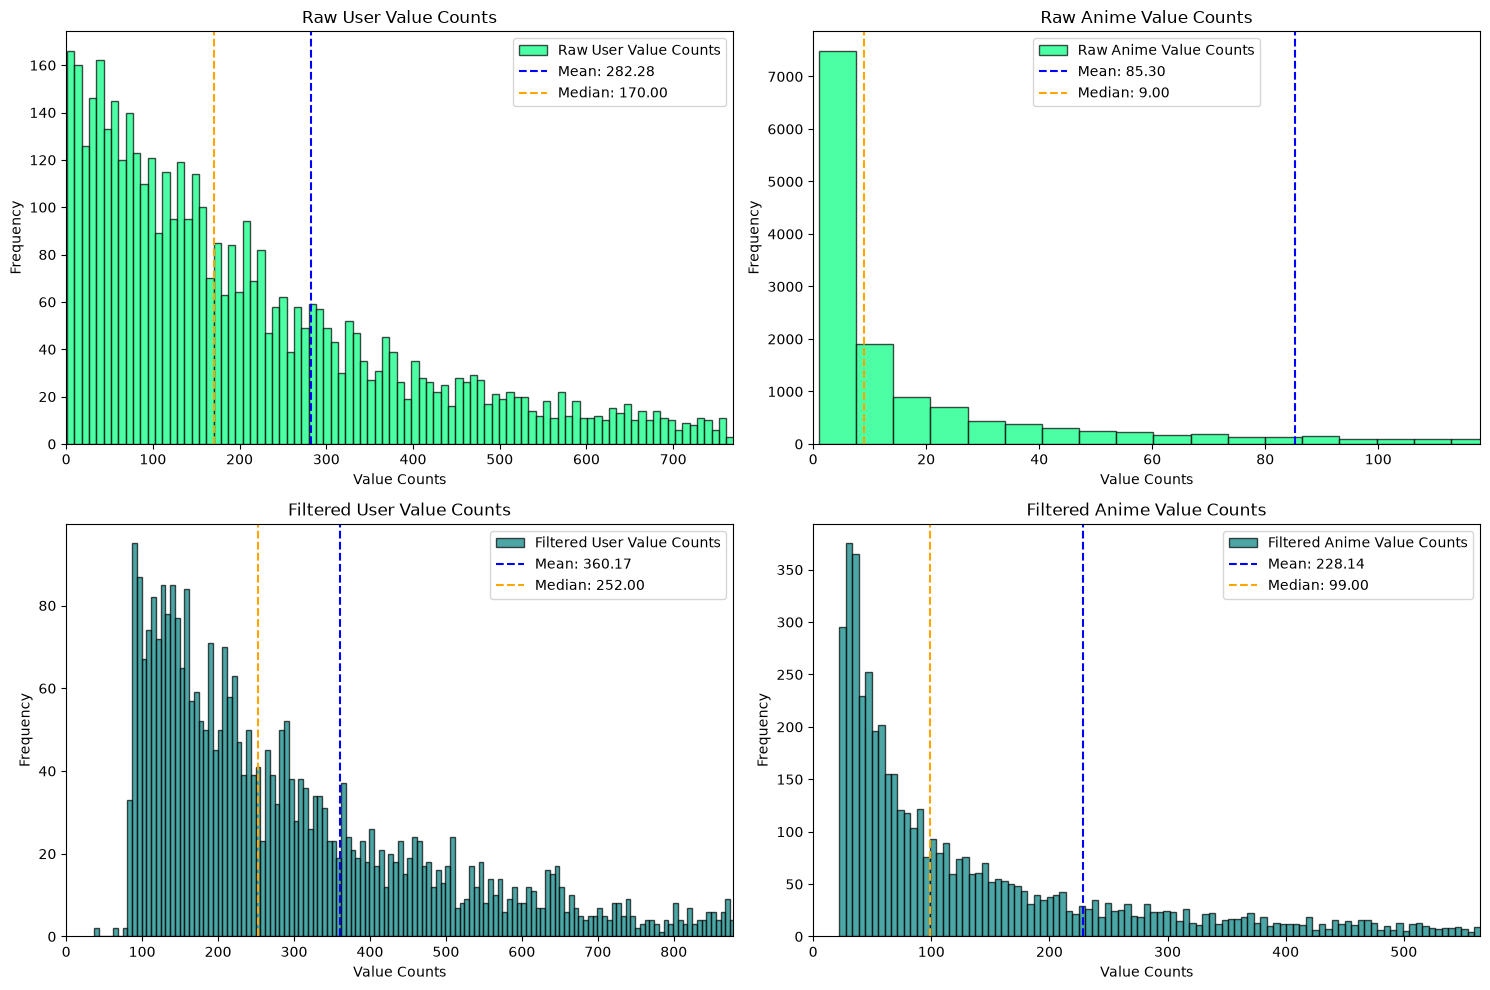

In [13]:
# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

panels = [
    (axes[0, 0], user_value_counts, user_mean, user_median, user_outlier_threshold, "springgreen", "Raw User Value Counts"),
    (axes[0, 1], anime_value_counts, anime_mean, anime_median, anime_outlier_threshold, "springgreen", "Raw Anime Value Counts"),
    (axes[1, 0], filtered_user_value_counts, filtered_user_mean, filtered_user_median, filtered_user_outlier_threshold, "teal", "Filtered User Value Counts"),
    (axes[1, 1], filtered_anime_value_counts, filtered_anime_mean, filtered_anime_median, filtered_anime_outlier_threshold, "teal", "Filtered Anime Value Counts"),
]

for ax, counts, mean, median, x_max, color, title in panels:
    ax.hist(counts, bins=500, edgecolor='k', alpha=0.7, color=color, label=title)
    ax.axvline(mean, color='blue', linestyle='--', label=f'Mean: {mean:.2f}')
    ax.axvline(median, color='orange', linestyle='--', label=f'Median: {median:.2f}')
    ax.set_title(title)
    ax.set_xlabel("Value Counts")
    ax.set_ylabel("Frequency")
    ax.set_xlim(0, x_max)
    ax.legend()

# Adjust layout and show the plot
plt.tight_layout()
plt.savefig(FIGURES / "anime_user_mean_median.png")
plt.show()

## Mean data exploration

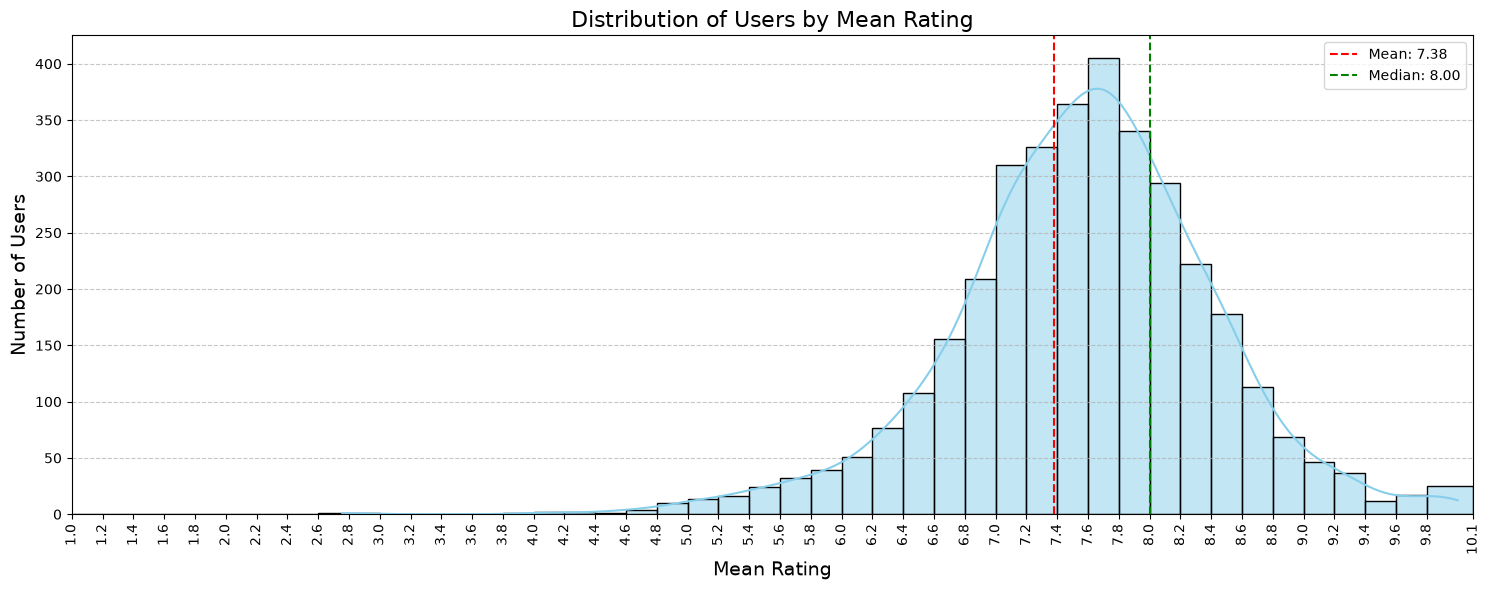

In [14]:
# Compute overall mean and median ratings
ratings_list = filtered_data["rating"].values
mean_mean = np.mean(ratings_list)
median_rating = np.median(ratings_list)

# Compute the mean rating for each user
mean_ratings = filtered_data.groupby("user_id")["rating"].mean()

# Define bins (1 to 10 in intervals of 0.2)
bins = np.append(np.arange(1, 10, 0.2), 10.1)

# Plot distribution using Seaborn histplot
plt.figure(figsize=(15, 6))
sns.histplot(mean_ratings, bins=bins, kde=True, color="skyblue", edgecolor="black")

# Add mean and median lines
plt.axvline(mean_mean, color='r', linestyle='--', label=f'Mean: {mean_mean:.2f}')
plt.axvline(median_rating, color='g', linestyle='--', label=f'Median: {median_rating:.2f}')

# Customize the plot
plt.title('Distribution of Users by Mean Rating', fontsize=16)
plt.xlabel('Mean Rating', fontsize=14)
plt.ylabel('Number of Users', fontsize=14)
plt.xticks(bins, rotation=90, fontsize=10)
plt.xlim(1, 10.1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(FIGURES / "mean_rating_distribution.png")
plt.show()

In [15]:
# Remove users given a mean rating, all users above that rating are removed from the dataset.
threshold = 9.0

# Compute the mean rating for each user
mean_ratings = filtered_data.groupby("user_id")["rating"].mean()
print(f"User count before filtering: {filtered_data['user_id'].nunique()}")
print(f"Mean rating before filtering: {np.mean(mean_ratings)}")

# Identify users with a mean rating above the threshold
users_to_remove = mean_ratings[mean_ratings > threshold].index

# Remove those users from the DataFrame
filtered_ratings_melted = filtered_data[~filtered_data["user_id"].isin(users_to_remove)]

print(f"User count after filtering: {filtered_ratings_melted['user_id'].nunique()}")
print(f"Mean rating after filtering: {filtered_ratings_melted.groupby('user_id')['rating'].mean().mean()}")

filtered_ratings_melted = filtered_ratings_melted.drop_duplicates(subset=['user_id', 'anime_title'], keep='last')

User count before filtering: 3506
Mean rating before filtering: 7.566249847412109
User count after filtering: 3370
Mean rating after filtering: 7.491694927215576


### Recalc Sparsity

In [16]:
user_item_matrix = filtered_ratings_melted.pivot(index='user_id', columns='anime_title', values='rating')

# Total number of entries in the matrix
total_entries = user_item_matrix.shape[0] * user_item_matrix.shape[1]

# Count the number of non-missing entries
non_missing_entries = user_item_matrix.count().sum()

# Calculate sparsity
sparsity = 1 - (non_missing_entries / total_entries)

print(f"Sparsity of the matrix after filtering: {sparsity:.2%}")

Sparsity of the matrix after filtering: 93.45%


### Save processed ratings

In [17]:
filtered_ratings_melted[["user_id", "anime_title", "rating"]].to_csv(DATA_PROCESSED / "ratings_long_filtered.csv", index=False)

## Sample stats and comparison

The population is the Kaggle *Anime Dataset 2023* (`user-filtered.csv`, ~1.5 GB), summarised into `data/external/` by `scripts/build_population_summary.py`. MAL records a rating of 0 for anime a user watched but did not score, so those rows are excluded; counting them as ratings would drag the population mean down to about 4.25.

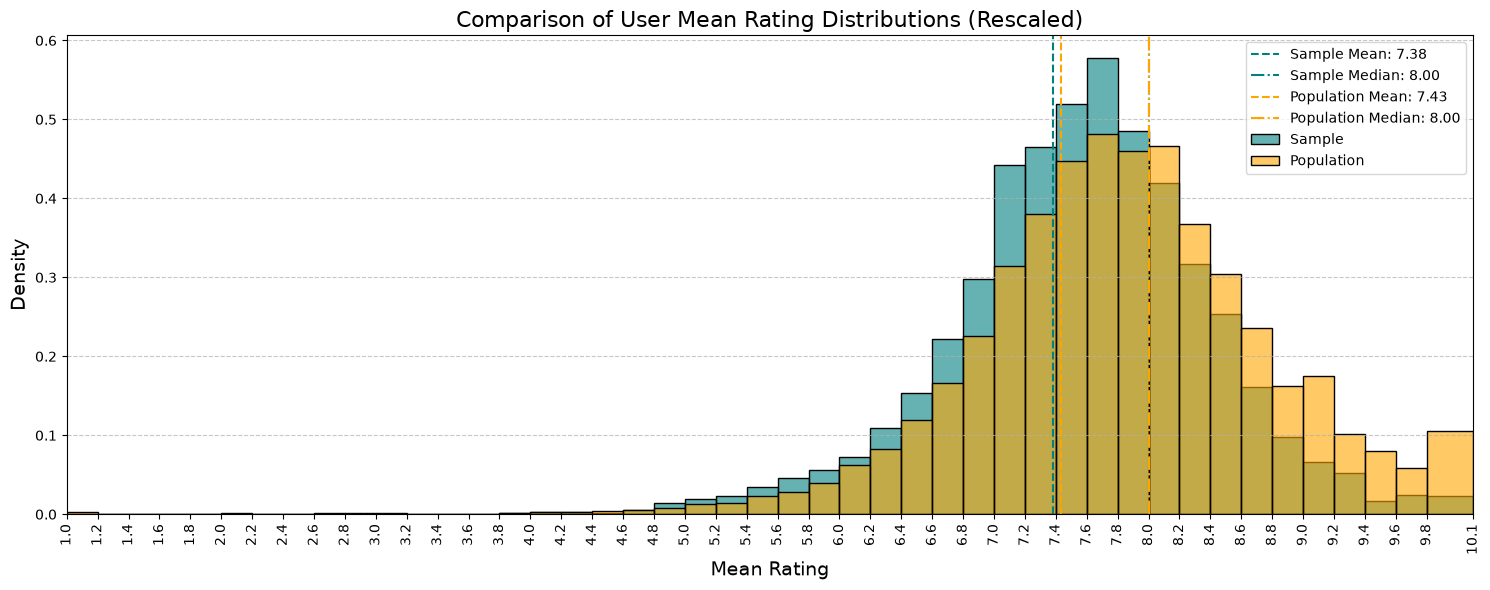

,Sample,Population
Unique Users,3506.00,313670.00
Mean,7.38,7.43
Median,8.00,8.00
Standard Deviation,1.70,1.77
Skewness,-0.79,-0.83
Kurtosis,1.08,1.03
Range,9.00,9.00


In [18]:
def weighted_rating_stats(ratings, counts):
    """Mean, median, standard deviation, skewness, excess kurtosis and range of ratings given as a frequency table."""
    ratings = np.asarray(ratings, dtype=float)
    counts = np.asarray(counts, dtype=float)
    n = counts.sum()

    mean = (ratings * counts).sum() / n
    central = ratings - mean
    m2, m3, m4 = ((counts * central**p).sum() / n for p in (2, 3, 4))

    order = np.argsort(ratings)
    median = ratings[order][np.searchsorted(np.cumsum(counts[order]), n / 2)]

    return {
        "Mean": mean,
        "Median": median,
        "Standard Deviation": np.sqrt(m2),
        "Skewness": m3 / m2**1.5,
        "Kurtosis": m4 / m2**2 - 3,
        "Range": ratings.max() - ratings.min(),
    }

population_counts = pd.read_csv(DATA_EXTERNAL / "population_rating_counts.csv")
population_user_means = pd.read_csv(DATA_EXTERNAL / "population_user_mean_ratings.csv")

# Sample statistics
sample_ratings_list = filtered_data["rating"].values
sample_mean_ratings = filtered_data.groupby("user_id")["rating"].mean()
sample_stats = {
    "Unique Users": filtered_data["user_id"].nunique(),
    "Mean": np.mean(sample_ratings_list),
    "Median": np.median(sample_ratings_list),
    "Standard Deviation": np.std(sample_ratings_list),
    "Skewness": skew(sample_ratings_list),
    "Kurtosis": kurtosis(sample_ratings_list),
    "Range": np.ptp(sample_ratings_list),
}

# Population statistics
population_mean_ratings = population_user_means["mean_rating"]
population_stats = {
    "Unique Users": len(population_user_means),
    **weighted_rating_stats(population_counts["rating"], population_counts["count"]),
}

# Define bins (1 to 10 in intervals of 0.2)
bins = np.append(np.arange(1, 10, 0.2), 10.1)

# Plot overlayed distributions
plt.figure(figsize=(15, 6))

sns.histplot(sample_mean_ratings, bins=bins, kde=False, color="teal", edgecolor="black", label="Sample", alpha=0.6, stat="density")
sns.histplot(population_mean_ratings, bins=bins, kde=False, color="orange", edgecolor="black", label="Population", alpha=0.6, stat="density")

plt.axvline(sample_stats["Mean"], color='teal', linestyle='--', label=f'Sample Mean: {sample_stats["Mean"]:.2f}')
plt.axvline(sample_stats["Median"], color='teal', linestyle='-.', label=f'Sample Median: {sample_stats["Median"]:.2f}')
plt.axvline(population_stats["Mean"], color='orange', linestyle='--', label=f'Population Mean: {population_stats["Mean"]:.2f}')
plt.axvline(population_stats["Median"], color='orange', linestyle='-.', label=f'Population Median: {population_stats["Median"]:.2f}')

plt.title('Comparison of User Mean Rating Distributions (Rescaled)', fontsize=16)
plt.xlabel('Mean Rating', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.xticks(bins, rotation=90, fontsize=10)
plt.xlim(1, 10.1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(FIGURES / "user_mean_comparison.png")
plt.show()

pd.DataFrame({"Sample": sample_stats, "Population": population_stats}).round(2)

#### Overlay anime mean rating stats with the above 2 distributions

https://www.reddit.com/r/anime/comments/mh868r/distribution_of_anime_scores_on_myanimelistnet/

## Genre spread

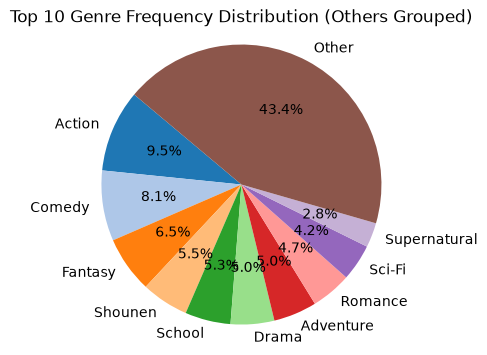

Top 10 Genres by Frequency:
Genre(s)
Action          1643
Comedy          1406
Fantasy         1124
Shounen          945
School           910
Drama            871
Adventure        865
Romance          807
Sci-Fi           732
Supernatural     492
Other           7496
Name: count, dtype: int64


In [19]:
anime_data = pd.read_csv(DATA_RAW / "anime_metadata.csv")

# Ensure 'Genre(s)' is split into lists
anime_data['Genre(s)'] = anime_data['Genre(s)'].str.split(", ")

# Explode the genres into individual rows
genres_exploded = anime_data.explode('Genre(s)')

# Count the frequency of each genre
genre_counts = genres_exploded['Genre(s)'].value_counts()

# Keep only the top 10 genres, group the rest as 'Other'
top_10_genres = genre_counts.head(10)
top_10_genres['Other'] = genre_counts[10:].sum()

# Plot the pie chart for genre frequency
plt.figure(figsize=(5, 4))
plt.pie(top_10_genres, labels=top_10_genres.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.tab20.colors)
plt.title("Top 10 Genre Frequency Distribution (Others Grouped)")
plt.axis('equal')  # Equal aspect ratio ensures the pie is circular
plt.savefig(FIGURES / "genre_split.png")
plt.show()

print("Top 10 Genres by Frequency:")
print(top_10_genres)

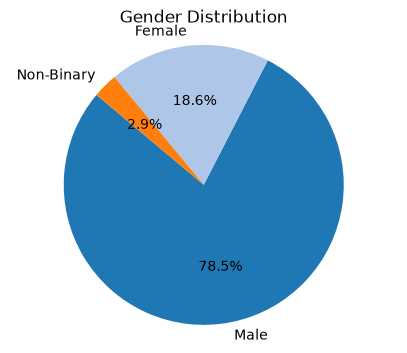

Gender counts:
Gender
Male          2512
Female         594
Non-Binary      92
Name: count, dtype: int64


In [20]:
user_data = pd.read_csv(DATA_RAW / "user_profiles.csv")

# Count the frequency of each gender
gender_counts = user_data['Gender'].value_counts()

# Plot the pie chart for gender split
plt.figure(figsize=(5, 4))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.tab20.colors)
plt.title("Gender Distribution")
plt.axis('equal')  # Equal aspect ratio ensures the pie is circular
plt.savefig(FIGURES / "gender_split.png")
plt.show()

print("Gender counts:")
print(gender_counts)

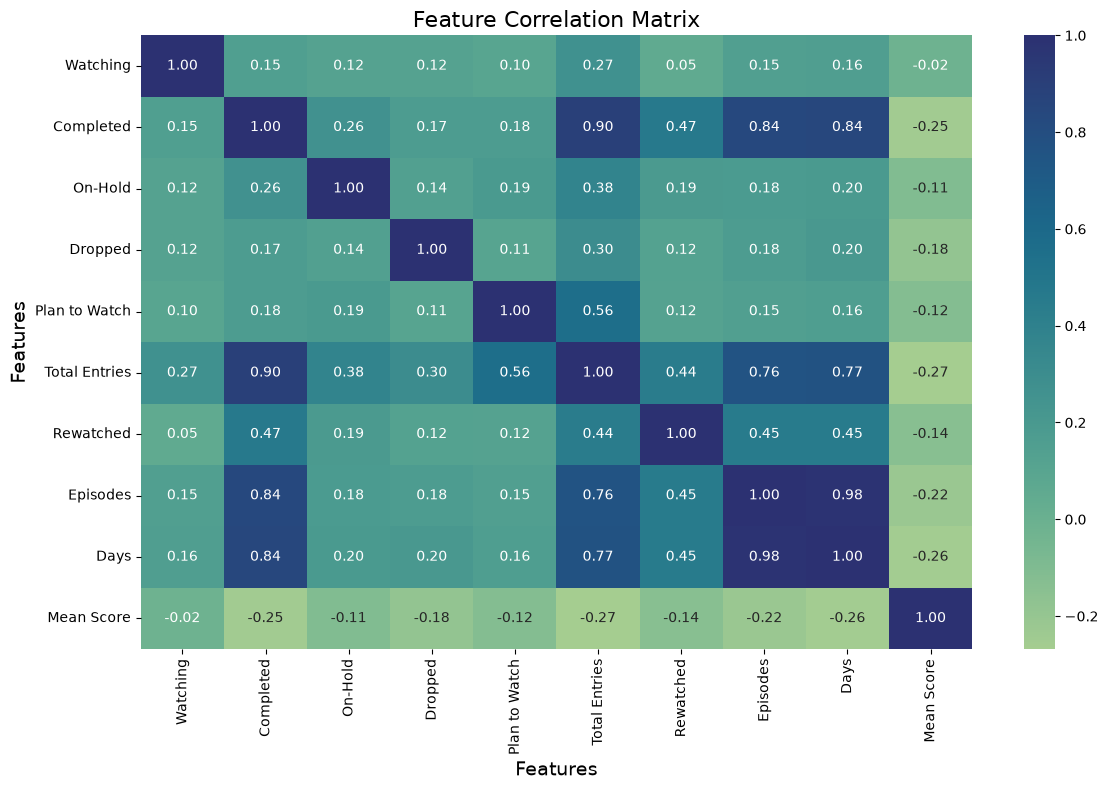

In [21]:
# Compute the correlation matrix
correlation_matrix = user_data.select_dtypes(include="number").corr()

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="crest", fmt=".2f", cbar=True)

plt.title("Feature Correlation Matrix", fontsize=16)
plt.xlabel("Features", fontsize=14)
plt.ylabel("Features", fontsize=14)

plt.tight_layout()
plt.savefig(FIGURES / "feature_matrix.png")
plt.show()

# Model Building

## Train / validation / test split

Every model is scored on the same held-out test set (20% of each user's ratings). Hyperparameters (neighbourhood sizes, hybrid weight) are tuned on a validation split carved out of the training data, so the test set is only used for the final scores.

In [22]:
def stratified_split(data, test_size=0.2, random_state=RANDOM_STATE):
    """Split each user's ratings into train/test so every user appears in both."""
    train_list = []
    test_list = []

    for _, group in data.groupby('user_id'):
        train_group, test_group = train_test_split(group, test_size=test_size, random_state=random_state)
        train_list.append(train_group)
        test_list.append(test_group)

    return pd.concat(train_list), pd.concat(test_list)


ratings = pd.read_csv(DATA_PROCESSED / "ratings_long_filtered.csv")

train_df, test_df = stratified_split(ratings, test_size=0.2)
tune_df, val_df = stratified_split(train_df, test_size=0.2)

print(f"Train: {len(train_df)} ratings (tune {len(tune_df)} + validation {len(val_df)}), test: {len(test_df)} ratings")

Train: 975454 ratings (tune 779043 + validation 196411), test: 245566 ratings


## Rating matrices and evaluation helpers

In [23]:
# Fixed user and anime orderings so every matrix lines up
user_index = pd.Index(np.sort(ratings["user_id"].unique()), name="user_id")
anime_index = pd.Index(np.sort(ratings["anime_title"].unique()), name="anime_title")


def rating_matrix(df):
    """Dense user x anime matrix of ratings, NaN where the user has not rated the anime."""
    R = np.full((len(user_index), len(anime_index)), np.nan, dtype=np.float32)
    R[user_index.get_indexer(df["user_id"]), anime_index.get_indexer(df["anime_title"])] = df["rating"].to_numpy()
    return R


def pair_indices(df):
    """Row/column positions and true ratings of the (user, anime) pairs in df."""
    return user_index.get_indexer(df["user_id"]), anime_index.get_indexer(df["anime_title"]), df["rating"].to_numpy()


def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": sqrt(mean_squared_error(y_true, y_pred))}


def recommend(user_id, R, predict, n_recommendations=10, min_support=5):
    """
    Top-N anime the user has not rated, ranked by predicted rating.

    `predict(users, items)` returns (predictions, support), where support is the number of
    neighbours behind each prediction. Anime with fewer than `min_support` neighbours are
    skipped so one enthusiastic neighbour cannot put an anime at the top of the list.
    """
    u = user_index.get_loc(user_id)
    unrated = np.flatnonzero(np.isnan(R[u]))
    preds, support = predict(np.full(len(unrated), u), unrated)

    recs = pd.DataFrame({"Anime Title": anime_index[unrated], "Predicted Rating": preds, "Neighbours": support})
    recs = recs[recs["Neighbours"] >= min_support]
    return recs.sort_values(["Predicted Rating", "Neighbours"], ascending=False).head(n_recommendations).reset_index(drop=True)


R_full, R_train, R_tune = rating_matrix(ratings), rating_matrix(train_df), rating_matrix(tune_df)
test_users, test_items, y_test = pair_indices(test_df)
val_users, val_items, y_val = pair_indices(val_df)

# One row per model: test MAE, RMSE and coverage (share of test ratings the model predicted itself rather than falling back to the baseline)
results = []

## Baselines

Any recommender has to beat these to be worth using. The user mean + item bias baseline is also the fallback for the kNN models when they have no neighbours to predict from.

In [24]:
def fit_baseline(R, item_reg=10):
    """
    User mean + item bias baseline.
    The item bias is how far above their own mean users rate the anime on average,
    shrunk towards 0 for anime with few ratings (item_reg acts like extra ratings of 0).
    """
    user_means = np.nanmean(R, axis=1)
    deviations = R - user_means[:, None]
    n_ratings = (~np.isnan(R)).sum(axis=0)
    item_bias = np.nansum(deviations, axis=0) / (n_ratings + item_reg)
    return user_means, item_bias


user_means_train, item_bias_train = fit_baseline(R_train)
user_means_tune, item_bias_tune = fit_baseline(R_tune)
global_mean = np.nanmean(R_train)

baseline_predictions = {
    "Global mean": np.full(len(y_test), global_mean),
    "User mean": user_means_train[test_users],
    "User mean + item bias": np.clip(user_means_train[test_users] + item_bias_train[test_items], 1, 10),
}
for name, preds in baseline_predictions.items():
    results.append({"Model": name, **score(y_test, preds), "Coverage": 1.0})

pd.DataFrame(results)

,Model,MAE,RMSE,Coverage
0,Global mean,1.295597,1.678286,1.0
1,User mean,1.113059,1.469369,1.0
2,User mean + item bias,0.948288,1.272141,1.0


## Collaborative Filtering (user-based kNN)

- **Similarity** is mean-centred cosine computed over the anime *both* users rated. Unrated anime stay missing instead of being filled with 0, so ratings below a user's mean count as evidence of disagreement and similarities can be negative.
- **Small overlaps are distrusted**: similarities are multiplied by `n_shared / (n_shared + 25)` and pairs sharing fewer than 5 anime are ignored, so two users who happen to agree on one or two shows are not treated as perfect matches.
- **Neighbours are chosen per anime** from the users who actually rated it, so every neighbour contributes to the prediction.
- Pairs with no qualifying neighbour fall back to the baseline, and the share of pairs the model predicted itself is reported as coverage.

### Functions

In [25]:
def user_similarity_matrix(R, shrinkage=25, min_overlap=5):
    """
    Mean-centred cosine similarity between every pair of users, using only the anime both rated.
    Similarities are shrunk towards 0 when the overlap is small and zeroed below min_overlap.
    """
    rated = ~np.isnan(R)
    user_means = np.nanmean(R, axis=1)
    X = np.where(rated, R - user_means[:, None], 0).astype(np.float32)
    M = rated.astype(np.float32)

    dot = X @ X.T                    # unrated entries are 0, so this sums over co-rated anime only
    sq_norms = (X ** 2) @ M.T        # [u, v] = sum of u's squared deviations over anime v also rated
    n_shared = M @ M.T

    with np.errstate(divide="ignore", invalid="ignore"):
        sim = dot / np.sqrt(sq_norms * sq_norms.T)
    sim = np.nan_to_num(sim) * (n_shared / (n_shared + shrinkage))
    sim[n_shared < min_overlap] = 0
    np.fill_diagonal(sim, 0)
    return sim.astype(np.float32)


def predict_user_knn(R, sim, user_means, item_bias, users, items, k=30):
    """
    Predict ratings for (user, anime) pairs with user-based kNN.

    For each anime, the neighbours are the k users most similar to the target user among
    those who rated it (positive similarities only). The prediction is the target user's mean
    plus the similarity-weighted average of the neighbours' mean-centred ratings.
    Pairs with no neighbour fall back to the baseline (user mean + item bias).

    Returns the predictions and the number of neighbours behind each one (0 = baseline).
    """
    deviations = R - user_means[:, None]
    preds = user_means[users] + item_bias[items]
    support = np.zeros(len(users), dtype=int)

    for item, positions in pd.Series(items).groupby(items).indices.items():
        raters = np.flatnonzero(~np.isnan(R[:, item]))
        if len(raters) == 0:
            continue
        target_users = users[positions]

        S = np.maximum(sim[np.ix_(target_users, raters)], 0)
        n = min(k, len(raters))
        top = np.argpartition(-S, n - 1, axis=1)[:, :n]
        weights = np.take_along_axis(S, top, axis=1)
        neighbour_deviations = deviations[raters, item][top]

        total_weight = weights.sum(axis=1)
        ok = total_weight > 0
        preds[positions[ok]] = user_means[target_users[ok]] + (weights * neighbour_deviations).sum(axis=1)[ok] / total_weight[ok]
        support[positions] = (weights > 0).sum(axis=1)

    return np.clip(preds, 1, 10), support

### Tune neighbourhood size on the validation set

In [26]:
sim_tune = user_similarity_matrix(R_tune)

cf_tuning = []
for k in [5, 10, 20, 30, 50, 100]:
    preds, support = predict_user_knn(R_tune, sim_tune, user_means_tune, item_bias_tune, val_users, val_items, k=k)
    cf_tuning.append({"k": k, **score(y_val, preds), "Coverage": (support > 0).mean()})

cf_tuning = pd.DataFrame(cf_tuning)
best_cf_k = int(cf_tuning.loc[cf_tuning["RMSE"].idxmin(), "k"])
print(f"Best k: {best_cf_k}")
cf_tuning

Best k: 50


,k,MAE,RMSE,Coverage
0,5,0.960609,1.284492,1.0
1,10,0.928975,1.248022,1.0
2,20,0.914664,1.231487,1.0
3,30,0.910864,1.227850,1.0
4,50,0.909585,1.227005,1.0
5,100,0.911824,1.229979,1.0


### Evaluation

In [27]:
# Similarities from training ratings only, so no test rating influences the neighbourhoods
sim_train = user_similarity_matrix(R_train)

cf_test_preds, cf_test_support = predict_user_knn(R_train, sim_train, user_means_train, item_bias_train, test_users, test_items, k=best_cf_k)
results.append({"Model": f"User-based CF (k={best_cf_k})", **score(y_test, cf_test_preds), "Coverage": (cf_test_support > 0).mean()})
results[-1]

{'Model': 'User-based CF (k=50)',
 'MAE': 0.9041552837005497,
 'RMSE': 1.2181368842052744,
 'Coverage': np.float64(1.0)}

#### Visualise similarity distribution

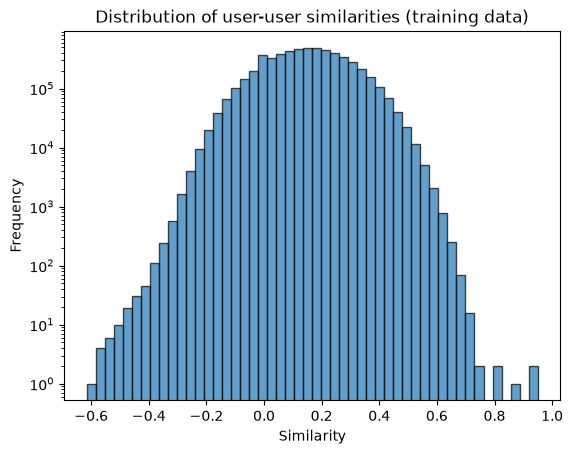

Negative: 13.3%, zero: 1.9%, max: 0.950


In [28]:
values = sim_train[np.triu_indices_from(sim_train, k=1)]

plt.hist(values, bins=50, edgecolor='k', alpha=0.7)
plt.title("Distribution of user-user similarities (training data)")
plt.xlabel("Similarity")
plt.ylabel("Frequency")
plt.yscale("log")
plt.show()

print(f"Negative: {(values < 0).mean():.1%}, zero: {(values == 0).mean():.1%}, max: {values.max():.3f}")

### Get recommendations for user

In [29]:
# Final model uses all ratings
sim_full = user_similarity_matrix(R_full)
user_means_full, item_bias_full = fit_baseline(R_full)

recommend(EXAMPLE_USER, R_full, lambda u, i: predict_user_knn(R_full, sim_full, user_means_full, item_bias_full, u, i, k=best_cf_k))

,Anime Title,Predicted Rating,Neighbours
0,Gintama°,9.663616,50
1,Shingeki no Kyojin Season 3 Part 2,9.588080,50
2,Ginga Eiyuu Densetsu,9.474186,50
3,Ashita no Joe 2,9.441482,50
4,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.432298,50
5,Gintama: The Final,9.387104,50
6,3-gatsu no Lion 2nd Season,9.378688,50
7,Vinland Saga Season 2,9.336675,50
8,Fruits Basket: The Final,9.312119,50
9,Clannad: After Story,9.298109,50


## Content-based Filtering

- **Predictions are on the rating scale**: the user's mean plus the similarity-weighted average of their mean-centred ratings of the *k* most similar anime they have rated (item-based kNN on content similarity).
- **Neighbours come from everything the user rated**, not only the target's stored top 5 similar anime, so far more pairs can be predicted.
- **Anime without metadata fall back to the baseline**, and coverage is reported so the error is comparable with the other models.
- Similarities are computed in one vectorised call and kept as a matrix. The top 15 similar anime per title are saved to `artifacts/anime_similarity_top15.csv` for inspection.

### Preprocessing and Model Build

In [30]:
anime_df = pd.read_csv(DATA_RAW / "anime_metadata.csv")

# A few titles map to several MAL entries; ratings are keyed by title, so keep the first
anime_df = anime_df.drop_duplicates(subset="Title", keep="first").reset_index(drop=True)

has_metadata = anime_index.isin(anime_df["Title"])
print(f"{has_metadata.sum()} of {len(anime_index)} rated anime have metadata ({has_metadata.mean():.1%})")
print(f"{has_metadata[test_items].mean():.1%} of test ratings are for anime with metadata")

3977 of 5535 rated anime have metadata (71.9%)
91.8% of test ratings are for anime with metadata


In [31]:
def split_labels(column):
    """Comma-separated labels to lists, with missing values as empty lists."""
    return column.fillna("").apply(lambda s: [label for label in s.split(", ") if label])


# Step 1: Numerical features (log-scaled episode count)
episode_count = np.log1p(anime_df[["Episode Count"]].fillna(0))
numerical_data = StandardScaler().fit_transform(episode_count)

# Step 2: One-Hot Encode Type
categorical_data = OneHotEncoder(sparse_output=False).fit_transform(anime_df[["Type"]].fillna("Unknown"))

# Step 3: Multi-Label Encode Genre(s) and Theme(s)
genre_data = MultiLabelBinarizer().fit_transform(split_labels(anime_df["Genre(s)"]))
theme_data = MultiLabelBinarizer().fit_transform(split_labels(anime_df["Theme(s)"]))

# Step 4: Synopsis semantic embeddings (all-MiniLM-L6-v2), cached in artifacts/.
# Encoding runs in a separate process because torch and numpy's MKL clash in one process on Windows.
embeddings_path = ARTIFACTS / "synopsis_embeddings.npy"
if not embeddings_path.exists():
    subprocess.run([sys.executable, "scripts/build_synopsis_embeddings.py"], check=True)
synopsis_data = np.load(embeddings_path)
assert len(synopsis_data) == len(anime_df), "Cached embeddings are out of date: delete artifacts/synopsis_embeddings.npy"

# Step 5: Apply feature weights to emphasise important features
genre_weight = 2.0
theme_weight = 1.75
synopsis_weight = 3.5
numerical_weight = 1.0
type_weight = 1.0

combined_features = np.hstack([
    numerical_data * numerical_weight,
    categorical_data * type_weight,
    genre_data * genre_weight,
    theme_data * theme_weight,
    synopsis_data * synopsis_weight,
])

# Step 6: Cosine similarity between all anime with metadata
content_sim = cosine_similarity(combined_features).astype(np.float32)

# Lay the similarities out on the rated-anime index (anime without metadata have no similarities)
meta_positions = pd.Index(anime_df["Title"]).get_indexer(anime_index)
rows = np.flatnonzero(meta_positions >= 0)
item_sim = np.zeros((len(anime_index), len(anime_index)), dtype=np.float32)
item_sim[np.ix_(rows, rows)] = content_sim[np.ix_(meta_positions[rows], meta_positions[rows])]
np.fill_diagonal(item_sim, 0)

In [32]:
# Step 7: Save the top 15 most similar anime for each title for inspection
top_n = 15
ranked = content_sim.copy()
np.fill_diagonal(ranked, -np.inf)
top_idx = np.argsort(-ranked, axis=1)[:, :top_n]

titles = anime_df["Title"].to_numpy()
similar_df = pd.DataFrame({
    "anime_title": np.repeat(titles, top_n),
    "rank": np.tile(np.arange(1, top_n + 1), len(titles)),
    "similar_title": titles[top_idx].ravel(),
    "similarity": np.take_along_axis(content_sim, top_idx, axis=1).ravel(),
})
similar_df.to_csv(ARTIFACTS / "anime_similarity_top15.csv", index=False)
similar_df.head(top_n)

,anime_title,rank,similar_title,similarity
0,"""Oshi no Ko""",1,"""Oshi no Ko"" 2nd Season",0.756906
1,"""Oshi no Ko""",2,Colorful (Movie),0.541613
2,"""Oshi no Ko""",3,Nami yo Kiitekure,0.530326
3,"""Oshi no Ko""",4,Ping Pong the Animation,0.483043
4,"""Oshi no Ko""",5,Seiyuu Radio no Uraomote,0.464869
5,"""Oshi no Ko""",6,Paripi Koumei,0.462110
6,"""Oshi no Ko""",7,"Tsuma, Shougakusei ni Naru.",0.457377
7,"""Oshi no Ko""",8,Tokyo Magnitude 8.0,0.456564
8,"""Oshi no Ko""",9,Rec,0.435148
9,"""Oshi no Ko""",10,Perfect Blue,0.430768


### Functions

In [33]:
def predict_content_knn(R, item_sim, user_means, item_bias, users, items, k=20):
    """
    Predict ratings for (user, anime) pairs from content similarity (item-based kNN).

    For each pair, the neighbours are the k anime most similar to the target that the user has
    rated (positive similarities only). The prediction is the user's mean plus the
    similarity-weighted average of their mean-centred ratings of those neighbours.
    Pairs with no neighbour (e.g. anime without metadata) fall back to the baseline.

    Returns the predictions and the number of neighbours behind each one (0 = baseline).
    """
    preds = user_means[users] + item_bias[items]
    support = np.zeros(len(users), dtype=int)

    for user, positions in pd.Series(users).groupby(users).indices.items():
        rated = np.flatnonzero(~np.isnan(R[user]))
        target_items = items[positions]

        S = np.maximum(item_sim[np.ix_(target_items, rated)], 0)
        n = min(k, len(rated))
        top = np.argpartition(-S, n - 1, axis=1)[:, :n]
        weights = np.take_along_axis(S, top, axis=1)
        neighbour_deviations = (R[user, rated] - user_means[user])[top]

        total_weight = weights.sum(axis=1)
        ok = total_weight > 0
        preds[positions[ok]] = user_means[user] + (weights * neighbour_deviations).sum(axis=1)[ok] / total_weight[ok]
        support[positions] = (weights > 0).sum(axis=1)

    return np.clip(preds, 1, 10), support

### Tune neighbourhood size on the validation set

In [34]:
cb_tuning = []
for k in [5, 10, 20, 30, 50]:
    preds, support = predict_content_knn(R_tune, item_sim, user_means_tune, item_bias_tune, val_users, val_items, k=k)
    cb_tuning.append({"k": k, **score(y_val, preds), "Coverage": (support > 0).mean()})

cb_tuning = pd.DataFrame(cb_tuning)
best_cb_k = int(cb_tuning.loc[cb_tuning["RMSE"].idxmin(), "k"])
print(f"Best k: {best_cb_k}")
cb_tuning

Best k: 20


,k,MAE,RMSE,Coverage
0,5,1.034144,1.404631,0.91781
1,10,1.030409,1.383341,0.91781
2,20,1.034028,1.380598,0.91781
3,30,1.038921,1.384246,0.91781
4,50,1.046782,1.391665,0.91781


### Evaluation

In [35]:
cb_test_preds, cb_test_support = predict_content_knn(R_train, item_sim, user_means_train, item_bias_train, test_users, test_items, k=best_cb_k)
results.append({"Model": f"Content-based (k={best_cb_k})", **score(y_test, cb_test_preds), "Coverage": (cb_test_support > 0).mean()})

# Error on the pairs the model could predict itself vs the baseline on those same pairs
covered = cb_test_support > 0
print("Covered pairs only - content-based:", score(y_test[covered], cb_test_preds[covered]))
print("Covered pairs only - user mean + item bias:", score(y_test[covered], baseline_predictions["User mean + item bias"][covered]))
results[-1]

Covered pairs only - content-based: {'MAE': 1.031365399523191, 'RMSE': 1.377079307893902}
Covered pairs only - user mean + item bias: {'MAE': 0.9461717032271434, 'RMSE': 1.2688264402236344}


{'Model': 'Content-based (k=20)',
 'MAE': 1.0265165706918233,
 'RMSE': 1.3716236824063839,
 'Coverage': np.float64(0.9182419390306475)}

### Make recommendation

In [36]:
recommend(EXAMPLE_USER, R_full, lambda u, i: predict_content_knn(R_full, item_sim, user_means_full, item_bias_full, u, i, k=best_cb_k))

,Anime Title,Predicted Rating,Neighbours
0,180-byou de Kimi no Mimi wo Shiawase ni Dekiru...,8.596744,20
1,Chi. Chikyuu no Undou ni Tsuite,8.551813,20
2,Akage no Anne,8.544669,20
3,Alps no Shoujo Heidi,8.497512,20
4,Ikoku Meiro no Croisée The Animation,8.463568,20
5,Versailles no Bara,8.443124,20
6,Master Keaton,8.441419,20
7,Ginga Eiyuu Densetsu,8.421557,20
8,Ginga Eiyuu Densetsu: Die Neue These - Sakubou,8.409966,20
9,Young Black Jack,8.395391,20


## Weighted Hybrid system

- Both components predict on the 1–10 rating scale, so a weighted average of them is meaningful.
- Every (user, anime) pair gets a blended score, so recommendations are ranked over all unrated anime rather than the union of two separate top lists.
- The CF component used for evaluation is built from training ratings only.
- The CF weight is chosen on the validation set, not the test set.

### Functions

In [37]:
def blend(cf_preds, cb_preds, weight):
    """Weighted average of CF and content-based predictions; weight is the share given to CF."""
    return weight * cf_preds + (1 - weight) * cb_preds


def predict_hybrid(R, sim, item_sim, user_means, item_bias, users, items, weight, k_cf, k_cb):
    """Blended predictions, with support taken from whichever component has more neighbours."""
    cf_preds, cf_support = predict_user_knn(R, sim, user_means, item_bias, users, items, k=k_cf)
    cb_preds, cb_support = predict_content_knn(R, item_sim, user_means, item_bias, users, items, k=k_cb)
    return blend(cf_preds, cb_preds, weight), np.maximum(cf_support, cb_support)

### Tune the CF weight on the validation set

In [38]:
cf_val_preds, _ = predict_user_knn(R_tune, sim_tune, user_means_tune, item_bias_tune, val_users, val_items, k=best_cf_k)
cb_val_preds, _ = predict_content_knn(R_tune, item_sim, user_means_tune, item_bias_tune, val_users, val_items, k=best_cb_k)

hybrid_tuning = pd.DataFrame([
    {"CF weight": weight, **score(y_val, blend(cf_val_preds, cb_val_preds, weight))}
    for weight in np.round(np.arange(0, 1.01, 0.1), 1)
])
best_weight = float(hybrid_tuning.loc[hybrid_tuning["RMSE"].idxmin(), "CF weight"])
print(f"Best CF weight: {best_weight}")
hybrid_tuning

Best CF weight: 0.8


,CF weight,MAE,RMSE
0,0.0,1.034028,1.380598
1,0.1,1.001439,1.340934
2,0.2,0.972547,1.305851
3,0.3,0.947752,1.275726
4,0.4,0.927433,1.250917
5,0.5,0.911850,1.231747
6,0.6,0.901256,1.218480
7,0.7,0.895732,1.211310
8,0.8,0.895287,1.210348
9,0.9,0.900000,1.215606


### Evaluation

In [39]:
hybrid_test_preds = blend(cf_test_preds, cb_test_preds, best_weight)
hybrid_coverage = ((cf_test_support > 0) | (cb_test_support > 0)).mean()
results.append({"Model": f"Hybrid (CF weight={best_weight})", **score(y_test, hybrid_test_preds), "Coverage": hybrid_coverage})
results[-1]

{'Model': 'Hybrid (CF weight=0.8)',
 'MAE': 0.8885826074702544,
 'RMSE': 1.2002076086361702,
 'Coverage': np.float64(1.0)}

### Make recommendations

In [40]:
recommend(EXAMPLE_USER, R_full, lambda u, i: predict_hybrid(
    R_full, sim_full, item_sim, user_means_full, item_bias_full, u, i,
    weight=best_weight, k_cf=best_cf_k, k_cb=best_cb_k,
))

,Anime Title,Predicted Rating,Neighbours
0,Gintama°,9.294359,50
1,Ginga Eiyuu Densetsu,9.263660,50
2,Shingeki no Kyojin Season 3 Part 2,9.190121,50
3,Ashita no Joe 2,9.156131,50
4,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.142092,50
5,3-gatsu no Lion 2nd Season,9.117283,50
6,Gintama.,9.061629,50
7,Monster,9.060809,50
8,Clannad: After Story,9.060010,50
9,Vinland Saga Season 2,9.043777,50


## Surprise SVD

### Preprocessing

In [41]:
# Define a Reader object with the appropriate rating scale
reader = Reader(rating_scale=(1, 10))

# Same train/test split as the other models
train_dataset = Dataset.load_from_df(train_df[['user_id', 'anime_title', 'rating']], reader)
trainset = train_dataset.build_full_trainset()

# Test set as a list of (user_id, anime_title, rating) tuples
testset = list(zip(test_df['user_id'], test_df['anime_title'], test_df['rating']))


def svd_result(name, predictions):
    coverage = np.mean([not p.details["was_impossible"] for p in predictions])
    return {"Model": name, "MAE": accuracy.mae(predictions, verbose=False), "RMSE": accuracy.rmse(predictions, verbose=False), "Coverage": coverage}

In [42]:
svd_model = SVD(random_state=RANDOM_STATE)
svd_model.fit(trainset)

predictions = svd_model.test(testset)
results.append(svd_result("SVD (default)", predictions))
results[-1]

{'Model': 'SVD (default)',
 'MAE': np.float64(0.8699938806954061),
 'RMSE': np.float64(1.1820371649700063),
 'Coverage': np.float64(1.0)}

In [43]:
# Parameter grid for SVD, searched with cross-validation on the training data only
param_grid = {
    'n_factors': [50, 100, 150],
    'lr_all': [0.002, 0.005],
    'reg_all': [0.02, 0.1],
    'random_state': [RANDOM_STATE],
}

gs = GridSearchCV(SVD, param_grid, measures=['rmse', 'mae'], cv=3, n_jobs=4)
gs.fit(train_dataset)
print(f'Best parameters: {gs.best_params["rmse"]}')

# Train the best model on the full training set and score it on the test set
best_svd = gs.best_estimator['rmse']
best_svd.fit(trainset)

best_predictions = best_svd.test(testset)
results.append(svd_result("SVD (tuned)", best_predictions))
results[-1]

Best parameters: {'n_factors': 150, 'lr_all': 0.005, 'reg_all': 0.1, 'random_state': 42}


{'Model': 'SVD (tuned)',
 'MAE': np.float64(0.8705314217999497),
 'RMSE': np.float64(1.175996848159056),
 'Coverage': np.float64(1.0)}

# Results

All models on the same test set. Coverage is the share of test ratings the model predicted itself; the rest fell back to the user mean + item bias baseline.

In [44]:
results_df = pd.DataFrame(results).set_index("Model").sort_values("RMSE")
results_df.round(4)

,MAE,RMSE,Coverage
Model,,,
SVD (tuned),0.8705,1.1760,1.0000
SVD (default),0.8700,1.1820,1.0000
Hybrid (CF weight=0.8),0.8886,1.2002,1.0000
User-based CF (k=50),0.9042,1.2181,1.0000
User mean + item bias,0.9483,1.2721,1.0000
Content-based (k=20),1.0265,1.3716,0.9182
User mean,1.1131,1.4694,1.0000
Global mean,1.2956,1.6783,1.0000
